# Section 2 — Le modèle linéaire : estimation et interprétation

**Projet d'économétrie appliquée** · Consommation d'énergie et rénovation thermique

**Entrée** : `data/processed/logements_propres.csv` (1 998 logements). **Sortie** : `data/processed/logements_modelisation.csv` (avec les variables en log et la période de construction, réutilisé par les notebooks suivants).

| § | Contenu |
|---|---|
| 2.1 | Régression simple $Conso_i=\beta_0+\beta_1 Surface_i+u_i$ |
| 2.2 | Régression multiple avec indicatrices de chauffage (référence : Électrique) |
| 2.3 | Modèles semi-log et log-log ; choix du modèle |
| 2.4 | Année de construction : variable continue ou indicatrices par période ? |

**Rappels du cours** (estimateur MCO, $X$ de plein rang) : $\hat b=(X'X)^{-1}X'y$ ; $V(\hat b_j)=\dfrac{\sigma^2}{(N-1)\,Var(X_j)}\,VIF_j$ ; $\bar R^2=1-(1-R^2)\dfrac{N-1}{N-k}$.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC, FIG, TAB = ROOT / "data" / "processed", ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"

df = pd.read_csv(PROC / "logements_propres.csv")
df["log_Conso"] = np.log(df["Conso_kWh"])
df["log_Surface"] = np.log(df["Surface_m2"])
df["log_DJU"] = np.log(df["DJU"])
df["log_Revenu"] = np.log(df["Revenu_kEUR"])
df["Periode"] = pd.cut(df["Annee_construction"], [-np.inf, 1947, 1974, 2000, 2012, np.inf],
                       labels=["Avant 1948", "1948-1974", "1975-2000", "2001-2012", "Après 2012"])
df.to_csv(PROC / "logements_modelisation.csv", index=False)
print("Observations :", len(df))
print(df["Periode"].value_counts().sort_index().to_dict())

CH = 'C(Chauffage, Treatment("Electrique"))'
PER = 'C(Periode, Treatment("Avant 1948"))'

def propre(nom):
    nom = nom.replace(f"{CH}[T.", "Chauffage : ").replace(f"{PER}[T.", "Période : ").replace("]", "")
    return nom

def tableau(m, nom_fichier=None):
    t = pd.DataFrame({"coef": m.params, "écart-type": m.bse, "t": m.tvalues, "p-valeur": m.pvalues,
                      "IC95 bas": m.conf_int()[0], "IC95 haut": m.conf_int()[1]})
    t.index = [propre(i) for i in t.index]
    if nom_fichier:
        t.round(4).to_csv(TAB / nom_fichier)
    return t

def ajustement(m):
    return pd.Series({"N": int(m.nobs), "k (paramètres)": int(m.df_model) + 1, "R²": m.rsquared,
                      "R² ajusté": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic})

Observations : 1998
{'Avant 1948': 444, '1948-1974': 528, '1975-2000': 612, '2001-2012': 245, 'Après 2012': 169}


## 2.1 Régression linéaire simple

In [2]:
m1 = smf.ols("Conso_kWh ~ Surface_m2", data=df).fit()
t1 = tableau(m1, "a5_modele_simple.csv")
display(t1.round(4))
display(ajustement(m1).round(4).to_frame("modèle simple").T)

b0, b1 = m1.params["Intercept"], m1.params["Surface_m2"]
print(f"β̂1 = {b1:.1f} kWh/m² (écart-type {m1.bse['Surface_m2']:.2f}, t = {m1.tvalues['Surface_m2']:.1f}, p < 0,001)")
print(f"β̂0 = {b0:.0f} kWh (écart-type {m1.bse['Intercept']:.0f}, t = {m1.tvalues['Intercept']:.2f}, p = {m1.pvalues['Intercept']:.3f})")
print(f"Surface minimale de l'échantillon : {df['Surface_m2'].min()} m²")

,coef,écart-type,t,p-valeur,IC95 bas,IC95 haut
Intercept,-272.9743,321.8856,-0.8480,0.3965,-904.2413,358.2927
Surface_m2,167.2166,3.1470,53.1352,0.0000,161.0448,173.3883


,N,k (paramètres),R²,R² ajusté,AIC,BIC
modèle simple,1998.0,2.0,0.5858,0.5856,40176.0157,40187.2155


β̂1 = 167.2 kWh/m² (écart-type 3.15, t = 53.1, p < 0,001)
β̂0 = -273 kWh (écart-type 322, t = -0.85, p = 0.397)
Surface minimale de l'échantillon : 15.0 m²


**Interprétation.**

- $\hat\beta_1$ : **un m² supplémentaire s'accompagne, en moyenne, de ≈ 167 kWh de consommation annuelle en plus.** Le coefficient est très significatif (statistique $t$ ≈ 53). Il s'agit d'une association moyenne : sans autres variables, la surface capte aussi l'effet des variables qui lui sont corrélées (occupants, maison).
- $\hat\beta_0$ : la constante est la consommation prédite pour une surface nulle. Elle **n'a pas de sens économique** : aucun logement n'a 0 m² (la plus petite surface observée est de 15 m²), c'est une extrapolation hors de l'échantillon. Elle est d'ailleurs statistiquement **non significative** (p ≈ 0,40) : elle sert à positionner la droite, non à être interprétée.
- $R^2\approx0{,}586$ : la surface seule explique près de 59 % de la variance de la consommation ; $\bar R^2$ est quasiment identique (un seul régresseur, $N$ grand).

## 2.2 Régression linéaire multiple

$$Conso_i=\beta_0+\beta_1 Surface_i+\beta_2 Nb\_occupants_i+\beta_3 Maison_i+\beta_4 Annee\_construction_i+\beta_5 DJU_i+\beta_6 Revenu_i+\sum_k\gamma_k\,\mathbb 1\{Chauffage_i=k\}+u_i$$

In [3]:
f2 = f"Conso_kWh ~ Surface_m2 + Nb_occupants + Maison + Annee_construction + DJU + Revenu_kEUR + {CH}"
m2 = smf.ols(f2, data=df).fit()
t2 = tableau(m2, "a5_modele_multiple_niveau.csv")
display(t2.round(4))
display(ajustement(m2).round(4).to_frame("modèle multiple (niveau)").T)

,coef,écart-type,t,p-valeur,IC95 bas,IC95 haut
Intercept,44653.7899,6076.9678,7.3480,0.0000,32735.8922,56571.6876
Chauffage : Bois,2491.0821,468.0654,5.3221,0.0000,1573.1316,3409.0326
Chauffage : Fioul,2384.2686,709.8319,3.3589,0.0008,992.1756,3776.3616
Chauffage : Gaz,268.5234,243.1700,1.1043,0.2696,-208.3714,745.4183
Chauffage : PAC,-4733.0642,369.8175,-12.7984,0.0000,-5458.3349,-4007.7934
Surface_m2,129.3975,4.2332,30.5676,0.0000,121.0956,137.6994
Nb_occupants,1250.0981,111.0452,11.2576,0.0000,1032.3208,1467.8753
Maison,554.3474,285.0537,1.9447,0.0520,-4.6881,1113.3829
Annee_construction,-28.3758,3.0402,-9.3336,0.0000,-34.3380,-22.4135
DJU,3.8400,0.3135,12.2469,0.0000,3.2250,4.4549


,N,k (paramètres),R²,R² ajusté,AIC,BIC
modèle multiple (niveau),1998.0,11.0,0.6962,0.6947,39574.7254,39636.3243


**Question 1 — Significativité et impact marginal de chaque variable** (en kWh/an, toutes choses égales par ailleurs)

In [4]:
lib = {"Surface_m2": "par m² supplémentaire", "Nb_occupants": "par occupant supplémentaire", "Maison": "maison plutôt qu'appartement",
       "Annee_construction": "par année de construction supplémentaire", "DJU": "par degré-jour unifié supplémentaire",
       "Revenu_kEUR": "par k€ de revenu supplémentaire"}
for v, texte in lib.items():
    c, p = m2.params[v], m2.pvalues[v]
    print(f"{v:20s} {c:+9.2f} kWh {texte:45s} p = {p:.4f}  {'significatif à 5 %' if p < .05 else 'NON significatif à 5 %'}")
print()
for k in ["Bois", "Fioul", "Gaz", "PAC"]:
    nom = f'{CH}[T.{k}]'
    c, p = m2.params[nom], m2.pvalues[nom]
    print(f"Chauffage {k:6s} vs Électrique : {c:+9.0f} kWh   p = {p:.4f}  {'significatif à 5 %' if p < .05 else 'NON significatif à 5 %'}")

Surface_m2             +129.40 kWh par m² supplémentaire                         p = 0.0000  significatif à 5 %
Nb_occupants          +1250.10 kWh par occupant supplémentaire                   p = 0.0000  significatif à 5 %
Maison                 +554.35 kWh maison plutôt qu'appartement                  p = 0.0520  NON significatif à 5 %
Annee_construction      -28.38 kWh par année de construction supplémentaire      p = 0.0000  significatif à 5 %
DJU                      +3.84 kWh par degré-jour unifié supplémentaire          p = 0.0000  significatif à 5 %
Revenu_kEUR             +29.99 kWh par k€ de revenu supplémentaire               p = 0.0000  significatif à 5 %

Chauffage Bois   vs Électrique :     +2491 kWh   p = 0.0000  significatif à 5 %
Chauffage Fioul  vs Électrique :     +2384 kWh   p = 0.0008  significatif à 5 %
Chauffage Gaz    vs Électrique :      +269 kWh   p = 0.2696  NON significatif à 5 %
Chauffage PAC    vs Électrique :     -4733 kWh   p = 0.0000  significatif à 5 %

**Réponse.** Tous les coefficients ne sont pas significatifs au seuil de 5 % : le **chauffage au gaz** (différence avec l'électrique non distinguable de 0) et, de justesse, **Maison** (p ≈ 0,052) ne le sont pas. Les autres variables (surface, occupants, année, DJU, revenu, PAC, bois, fioul) le sont. L'impact marginal de chaque variable est la valeur de son coefficient, exprimée en kWh par unité : par exemple environ +129 kWh par m², +1 250 kWh par occupant, et environ −28 kWh par année de construction plus récente (soit ≈ −284 kWh par décennie). Pour les variables non significatives, on ne conclut pas à un effet nul : on ne peut simplement pas le distinguer de 0 avec ces données.

**Question 2 — Combien d'indicatrices pour `Chauffage` ?**

In [5]:
# Piège des variables indicatrices : K modalités => K-1 indicatrices (la modalité omise est la référence).
tous = pd.get_dummies(df["Chauffage"]).astype(float)
X_piege = tous.copy(); X_piege.insert(0, "const", 1.0)
print(f"Modalités de Chauffage : {df['Chauffage'].nunique()} -> {df['Chauffage'].nunique() - 1} indicatrices à introduire")
print(f"Avec les {tous.shape[1]} indicatrices ET la constante : colonnes = {X_piege.shape[1]}, rang de X = {np.linalg.matrix_rank(X_piege.values)}")
print("Somme des 5 indicatrices == constante pour toutes les lignes :", bool((tous.sum(axis=1) == 1).all()))
print(f"Nombre de conditionnement de X'X : {np.linalg.cond(X_piege.values.T @ X_piege.values):.2e} (matrice singulière)")

Modalités de Chauffage : 5 -> 4 indicatrices à introduire
Avec les 5 indicatrices ET la constante : colonnes = 6, rang de X = 5
Somme des 5 indicatrices == constante pour toutes les lignes : True
Nombre de conditionnement de X'X : 5.68e+16 (matrice singulière)


**Réponse.** Il faut **4 indicatrices** pour 5 modalités. La somme des 5 indicatrices vaut exactement 1 pour chaque logement, soit la constante : si on les introduit toutes avec la constante, la matrice $X$ n'est plus de plein rang (rang 5 pour 6 colonnes), $X'X$ est singulière et $\hat b=(X'X)^{-1}X'y$ **n'est pas calculable** : c'est la **multicolinéarité parfaite** (cours « Multicollinearity »). Un logiciel retire arbitrairement une colonne ou renvoie une solution arbitraire. La modalité omise (ici **Électrique**) devient la référence, et chaque $\hat\gamma_k$ se lit comme l'écart par rapport à elle.

In [6]:
g = m2.params[f'{CH}[T.PAC]']; lo, hi = m2.conf_int().loc[f'{CH}[T.PAC]']
print(f"γ̂_PAC = {g:.0f} kWh/an (IC 95 % : [{lo:.0f} ; {hi:.0f}])")
print(f"Maison : coefficient = {m2.params['Maison']:.0f} kWh, p = {m2.pvalues['Maison']:.3f}")
print(f"R² = {m2.rsquared:.4f}  ;  R² ajusté = {m2.rsquared_adj:.4f}  ; écart = {m2.rsquared - m2.rsquared_adj:.4f}")

γ̂_PAC = -4733 kWh/an (IC 95 % : [-5458 ; -4008])
Maison : coefficient = 554 kWh, p = 0.052
R² = 0.6962  ;  R² ajusté = 0.6947  ; écart = 0.0015


**Interprétation de $\hat\gamma_{PAC}$.** À surface, occupants, type de logement, année, climat et revenu identiques, un logement chauffé par **pompe à chaleur consomme en moyenne ≈ 4 733 kWh de moins par an** qu'un logement chauffé à l'électrique (IC 95 % : ≈ [−5 458 ; −4 008]). C'est cohérent avec le rendement d'une PAC (coefficient de performance supérieur à 1 contre un rendement de 1 pour les convecteurs).

**Question 3 — Coefficient de `Maison`.** À surface, nombre d'occupants, année, climat, revenu et chauffage identiques, une maison consomme en moyenne **≈ 554 kWh de plus** qu'un appartement, mais l'effet est **à la limite de la significativité** (p ≈ 0,052). L'effet brut (maisons plus grandes) a été absorbé par la surface : il reste surtout la plus grande exposition des murs et toitures aux déperditions. L'ordre de grandeur est faible par rapport à l'effet de la surface.

**Question 4 — $R^2$ et $\bar R^2$.** $R^2\approx0{,}696$ : le modèle explique près de 70 % de la variance de la consommation. $R^2$ ne peut que croître quand on ajoute des variables, même inutiles ; $\bar R^2$ ($\approx0{,}695$) **pénalise le nombre de régresseurs** en corrigeant par les degrés de liberté. L'écart est minime parce que $N=1\,998$ est grand par rapport à $k=11$ : aucune variable n'est ajoutée « pour rien » de façon massive. On utilise $\bar R^2$ (ou AIC/BIC) pour comparer des modèles de taille différente.

## 2.3 Transformations logarithmiques

- **Semi-log** : $\log Conso_i=\beta_0+\beta_1 Surface_i+\dots+u_i$ (variables explicatives en niveau).
- **Log-log** : $\log Conso_i=\beta_0+\beta_1\log Surface_i+\beta_2 Nb\_occupants_i+\beta_3 Maison_i+\beta_4 Annee_i+\beta_5\log DJU_i+\beta_6\log Revenu_i+\sum_k\gamma_k\mathbb 1\{Chauffage_i=k\}+u_i$

Le nombre d'occupants, `Maison`, l'année et les indicatrices restent en niveau (la variable `Nb_occupants` peut valoir de petits entiers ; `Maison` est binaire).

In [7]:
f3 = f"log_Conso ~ Surface_m2 + Nb_occupants + Maison + Annee_construction + DJU + Revenu_kEUR + {CH}"
f4 = f"log_Conso ~ log_Surface + Nb_occupants + Maison + Annee_construction + log_DJU + log_Revenu + {CH}"
m3 = smf.ols(f3, data=df).fit(); m4 = smf.ols(f4, data=df).fit()
print("=== Modèle SEMI-LOG ==="); display(tableau(m3, "a5_modele_semilog.csv").round(4))
print("=== Modèle LOG-LOG ===");  display(tableau(m4, "a5_modele_loglog.csv").round(4))

=== Modèle SEMI-LOG ===


,coef,écart-type,t,p-valeur,IC95 bas,IC95 haut
Intercept,11.4984,0.3272,35.1411,0.0000,10.8567,12.1401
Chauffage : Bois,0.1289,0.0252,5.1140,0.0000,0.0795,0.1783
Chauffage : Fioul,0.0809,0.0382,2.1163,0.0344,0.0059,0.1558
Chauffage : Gaz,0.0208,0.0131,1.5880,0.1124,-0.0049,0.0465
Chauffage : PAC,-0.3774,0.0199,-18.9514,0.0000,-0.4164,-0.3383
Surface_m2,0.0075,0.0002,32.9358,0.0000,0.0071,0.0080
Nb_occupants,0.0764,0.0060,12.7856,0.0000,0.0647,0.0882
Maison,0.0985,0.0153,6.4189,0.0000,0.0684,0.1286
Annee_construction,-0.0018,0.0002,-11.2128,0.0000,-0.0022,-0.0015
DJU,0.0002,0.0000,14.2666,0.0000,0.0002,0.0003


=== Modèle LOG-LOG ===


,coef,écart-type,t,p-valeur,IC95 bas,IC95 haut
Intercept,4.7367,0.4471,10.5937,0.0000,3.8598,5.6135
Chauffage : Bois,0.1197,0.0244,4.9120,0.0000,0.0719,0.1674
Chauffage : Fioul,0.0710,0.0369,1.9222,0.0547,-0.0014,0.1435
Chauffage : Gaz,0.0195,0.0127,1.5424,0.1231,-0.0053,0.0444
Chauffage : PAC,-0.3754,0.0193,-19.4982,0.0000,-0.4132,-0.3376
log_Surface,0.7325,0.0204,35.8550,0.0000,0.6924,0.7726
Nb_occupants,0.0826,0.0056,14.7761,0.0000,0.0717,0.0936
Maison,0.0446,0.0154,2.8930,0.0039,0.0144,0.0748
Annee_construction,-0.0018,0.0002,-11.2624,0.0000,-0.0021,-0.0015
log_DJU,0.5781,0.0383,15.0859,0.0000,0.5030,0.6533


In [8]:
print("LOG-LOG : élasticités")
for v, nom in [("log_Surface", "surface"), ("log_DJU", "DJU"), ("log_Revenu", "revenu")]:
    c, p = m4.params[v], m4.pvalues[v]
    print(f"  {nom:8s} : {c:.4f}  ->  +1 % de {nom} => {c:+.2f} % de consommation  (p = {p:.4g})")
bm = m3.params["Maison"]
print(f"LOG-LOG : Maison = {m4.params['Maison']:.4f}  ->  {np.expm1(m4.params['Maison']) * 100:+.1f} %  (p = {m4.pvalues['Maison']:.4f})")
print(f"\nSEMI-LOG : Maison = {bm:.4f}  ->  effet exact = exp({bm:.4f}) - 1 = {np.expm1(bm) * 100:+.1f} %  (approximation 100·β = {100 * bm:.1f} %), p = {m3.pvalues['Maison']:.4f}")

LOG-LOG : élasticités
  surface  : 0.7325  ->  +1 % de surface => +0.73 % de consommation  (p = 1.485e-217)
  DJU      : 0.5781  ->  +1 % de DJU => +0.58 % de consommation  (p = 9.055e-49)
  revenu   : 0.0735  ->  +1 % de revenu => +0.07 % de consommation  (p = 4.918e-09)
LOG-LOG : Maison = 0.0446  ->  +4.6 %  (p = 0.0039)

SEMI-LOG : Maison = 0.0985  ->  effet exact = exp(0.0985) - 1 = +10.4 %  (approximation 100·β = 9.9 %), p = 0.0000


**Interprétations (log-log).**

- **Surface** : élasticité $\hat\beta\approx0{,}73$ : une surface supérieure de 1 % augmente la consommation d'environ 0,73 %. Une élasticité **inférieure à 1 est plausible** : une grande surface ne se chauffe pas proportionnellement (économies d'échelle : murs mitoyens, pièces peu occupées, eau chaude et appareils qui dépendent du nombre d'occupants et non de la surface). L'hypothèse d'élasticité égale à 1 (consommation proportionnelle) sera testée formellement en partie 4.
- **DJU** : élasticité ≈ 0,58 : un climat 1 % plus rigoureux augmente la consommation de 0,58 %. Elle est inférieure à 1 car une partie de la consommation (eau chaude, électroménager, éclairage) ne dépend pas du climat.
- **Revenu** : élasticité ≈ 0,07 : faible mais significative ; les ménages plus aisés consomment un peu plus (équipements, confort), à surface et occupants donnés.

**Interprétation de `Maison` en semi-log.** Le coefficient est ≈ 0,0985 : une maison consomme en moyenne **+10,4 %** de plus qu'un appartement à caractéristiques égales ($e^{0{,}0985}-1$, l'approximation 100·β ≈ 9,9 % sous-estime légèrement pour des coefficients non négligeables). Remarque : en log-log, l'effet de `Maison` est nettement plus faible (voir la sortie ci-dessus), car la spécification en log de la surface absorbe différemment l'effet de la taille.

**Peut-on comparer le $R^2$ du niveau avec celui du log ? Quel modèle retenir ?**

In [9]:
def retransforme(m):
    # Estimateur de lissage de Duan : Ψ = moyenne(exp(û)) ; prédiction en kWh = exp(prédiction en log) × Ψ
    psi = np.mean(np.exp(m.resid))
    yhat = np.exp(m.fittedvalues) * psi
    return psi, yhat

lignes = []
for nom, m, en_log in [("Niveau", m2, False), ("Semi-log", m3, True), ("Log-log", m4, True)]:
    if en_log:
        psi, yhat = retransforme(m)
    else:
        psi, yhat = 1.0, m.fittedvalues
    r = m.resid
    lignes.append({"modèle": nom, "variable expliquée": "log Conso" if en_log else "Conso (kWh)",
                   "R² (échelle propre)": m.rsquared, "R² sur l'échelle kWh": np.corrcoef(yhat, df["Conso_kWh"])[0, 1] ** 2,
                   "RMSE (kWh)": np.sqrt(np.mean((df["Conso_kWh"] - yhat) ** 2)),
                   "asymétrie résidus": stats.skew(r), "kurtosis résidus": stats.kurtosis(r, fisher=False),
                   "p Jarque-Bera résidus": stats.jarque_bera(r).pvalue, "p Breusch-Pagan": het_breuschpagan(r, m.model.exog)[1]})
comp = pd.DataFrame(lignes).set_index("modèle")
comp.round(4).to_csv(TAB / "a5_comparaison_modeles.csv")
comp.round(4)

,variable expliquée,R² (échelle propre),R² sur l'échelle kWh,RMSE (kWh),asymétrie résidus,kurtosis résidus,p Jarque-Bera résidus,p Breusch-Pagan
modèle,,,,,,,,
Niveau,Conso (kWh),0.6962,0.6962,4813.3130,1.4165,8.9638,0.0000,0.0
Semi-log,log Conso,0.7542,0.6651,5254.0047,-0.0012,3.3715,0.0032,0.0
Log-log,log Conso,0.7702,0.7199,4626.5514,0.0811,3.2608,0.0197,0.0


**Réponse.**

- **Non, on ne peut pas comparer directement les $R^2$** des modèles en niveau et en log : ils n'expliquent pas la même variable ($Conso$ contre $\log Conso$), donc leur somme totale des carrés est différente. Le $R^2$ du semi-log (≈ 0,754) n'est pas « meilleur » que celui du niveau (≈ 0,696) pour cette seule raison. De même, l'AIC/BIC de modèles dont la variable expliquée diffère ne sont pas comparables sans correction.
- **Comparaison équitable** : on revient à l'échelle des kWh en retransformant les prédictions des modèles en log par l'estimateur de Duan ($\hat\Psi=\frac1N\sum e^{\hat u_i}$, voir cours « Log and predictions »). Sur l'échelle kWh, le **log-log est le meilleur** : $R^2\approx0{,}720$ (contre 0,696 pour le niveau et 0,665 pour le semi-log) et RMSE ≈ 4 627 kWh (contre 4 813 et 5 254). Le semi-log fait *moins bien* que le niveau sur cette échelle.
- **Qualité des résidus** : en niveau, les résidus sont très asymétriques (1,42) avec des queues épaisses (kurtosis 8,96) : la normalité est rejetée (Jarque-Bera p ≈ 0). En log-log, ils sont quasi normaux (asymétrie 0,08, kurtosis 3,26) : Jarque-Bera rejette encore légèrement la normalité (p ≈ 0,02) avec l'année en variable linéaire, mais ne la rejette plus une fois la période de construction modélisée par indicatrices (p ≈ 0,22, §2.4). Dans tous les cas c'est bien meilleur qu'en niveau (p ≈ 0).
- **Retenu : le modèle log-log.** Meilleur ajustement sur l'échelle des kWh, résidus quasi gaussiens (aide à la validité des tests classiques), coefficients interprétables en élasticités.
- **Limite à signaler** : le test de Breusch-Pagan rejette l'homoscédasticité dans les trois modèles (p ≈ 10⁻¹⁷ en log-log) : le passage au log **ne règle pas** le problème d'hétéroscédasticité. Il sera traité en partie 5 (écarts-types robustes, MCG réalisables).

## 2.4 Une variable continue ou des indicatrices ?

La première réglementation thermique date de 1974, renforcée en 2000 et en 2012. On remplace `Annee_construction` par la période de construction (avant 1948 = référence, 1948-1974, 1975-2000, 2001-2012, après 2012), dans le modèle log-log retenu.

In [10]:
base = "log_Conso ~ log_Surface + Nb_occupants + Maison + log_DJU + log_Revenu + " + CH
ma = smf.ols(base + " + Annee_construction", data=df).fit()                 # (A) année linéaire
mb = smf.ols(base + " + " + PER, data=df).fit()                              # (B) indicatrices de période
mc = smf.ols(base + " + Annee_construction + " + PER, data=df).fit()         # (C) les deux

crit = pd.DataFrame({"(A) année linéaire": ajustement(ma), "(B) indicatrices": ajustement(mb), "(C) les deux": ajustement(mc)}).T
crit.round(4).to_csv(TAB / "a5_criteres_periode.csv")
display(crit.round(4))

F_dummies, p_dummies, df_d = mc.compare_f_test(ma)    # (C) contre (A) : apport des indicatrices
F_lin, p_lin, df_l = mc.compare_f_test(mb)            # (C) contre (B) : apport de la variable linéaire
print(f"Test F : indicatrices de période ajoutées au modèle linéaire : F = {F_dummies:.2f} (ddl = {df_d:.0f}), p = {p_dummies:.2e}")
print(f"Test F : année linéaire ajoutée au modèle à indicatrices     : F = {F_lin:.3f} (ddl = {df_l:.0f}), p = {p_lin:.3f}")
display(tableau(mb, "a5_modele_loglog_periodes.csv").round(4))
effets = np.expm1(mb.params[[f'{PER}[T.{p}]' for p in ["1948-1974", "1975-2000", "2001-2012", "Après 2012"]]]) * 100
print("\nEffet en % par rapport à « Avant 1948 » :"); print(effets.round(1).rename(lambda s: propre(s)).to_string())

,N,k (paramètres),R²,R² ajusté,AIC,BIC
(A) année linéaire,1998.0,11.0,0.7702,0.7690,161.8723,223.4712
(B) indicatrices,1998.0,14.0,0.7753,0.7738,123.1136,201.5122
(C) les deux,1998.0,15.0,0.7753,0.7737,125.0471,209.0456


Test F : indicatrices de période ajoutées au modèle linéaire : F = 11.25 (ddl = 4), p = 5.02e-09
Test F : année linéaire ajoutée au modèle à indicatrices     : F = 0.066 (ddl = 1), p = 0.797


,coef,écart-type,t,p-valeur,IC95 bas,IC95 haut
Intercept,1.2873,0.3061,4.2057,0.0000,0.6870,1.8875
Chauffage : Bois,0.1171,0.0241,4.8547,0.0000,0.0698,0.1644
Chauffage : Fioul,0.0707,0.0366,1.9334,0.0533,-0.0010,0.1425
Chauffage : Gaz,0.0236,0.0125,1.8790,0.0604,-0.0010,0.0482
Chauffage : PAC,-0.3577,0.0195,-18.3544,0.0000,-0.3959,-0.3195
Période : 1948-1974,-0.0183,0.0161,-1.1374,0.2555,-0.0499,0.0133
Période : 1975-2000,-0.1187,0.0158,-7.5331,0.0000,-0.1496,-0.0878
Période : 2001-2012,-0.1624,0.0200,-8.1226,0.0000,-0.2016,-0.1232
Période : Après 2012,-0.2320,0.0232,-10.0155,0.0000,-0.2774,-0.1866
log_Surface,0.7322,0.0202,36.2042,0.0000,0.6925,0.7718



Effet en % par rapport à « Avant 1948 » :
Période : 1948-1974     -1.8
Période : 1975-2000    -11.2
Période : 2001-2012    -15.0
Période : Après 2012   -20.7


Log-log avec indicatrices de période : R² sur l'échelle kWh = 0.7244, RMSE = 4590 kWh, Ψ de Duan = 1.0313


Résidus : asymétrie = 0.044, kurtosis = 3.171, p Jarque-Bera = 0.217


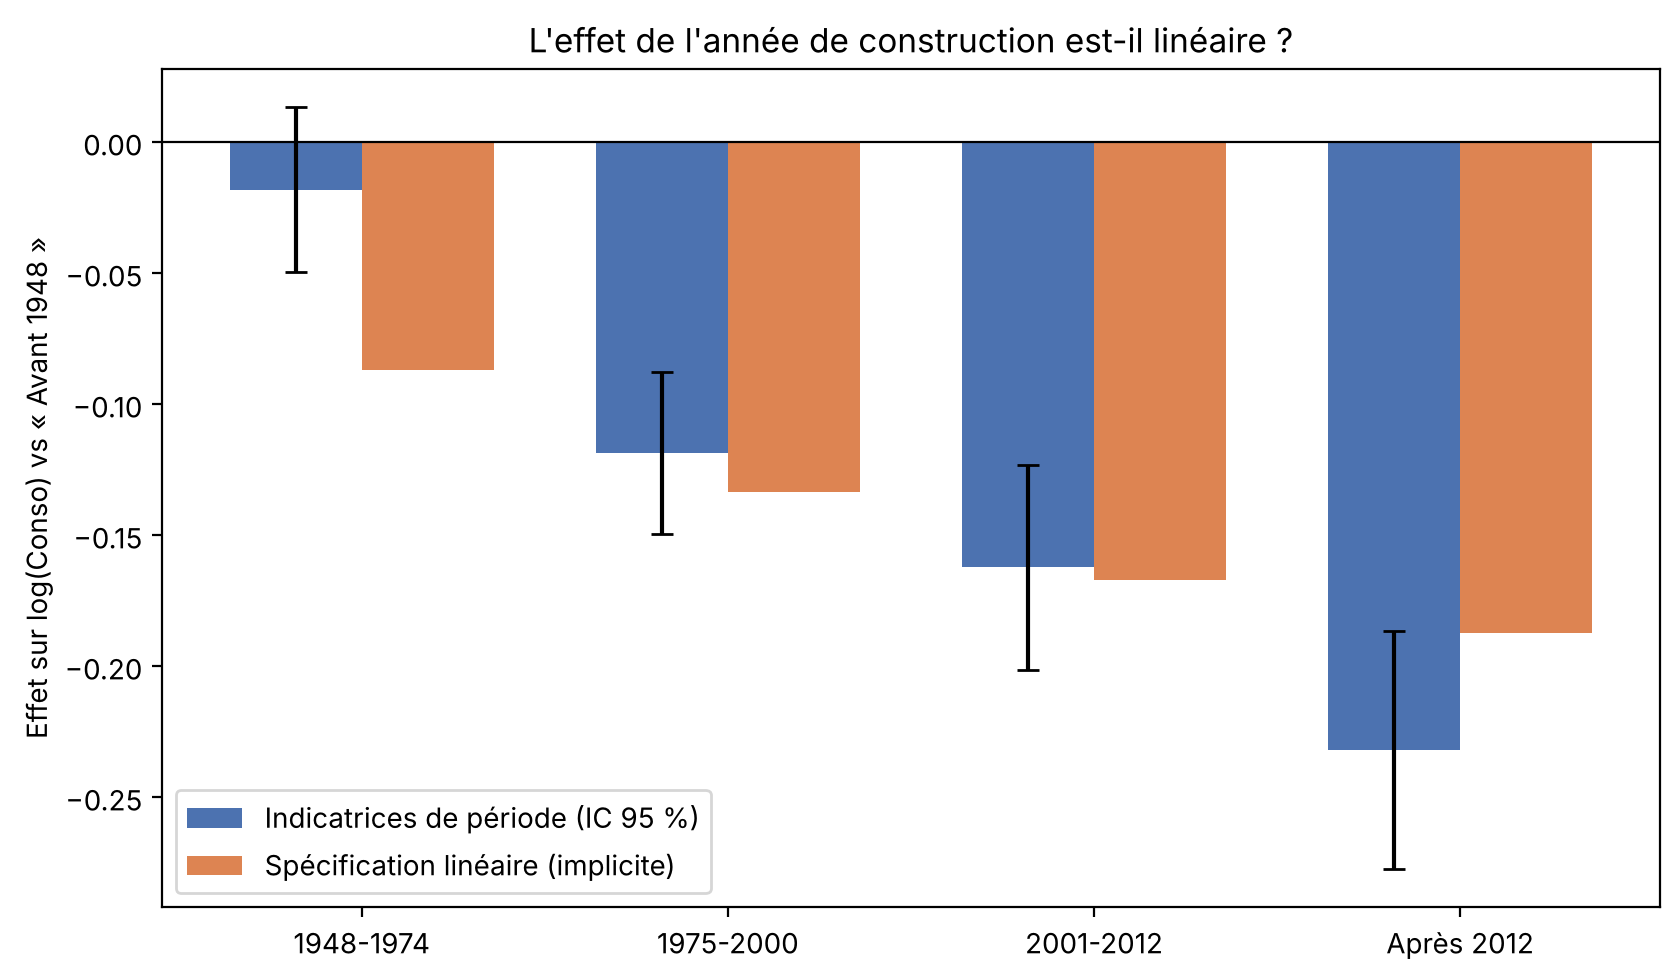

In [11]:
psi_b, yhat_b = retransforme(mb)
print(f"Log-log avec indicatrices de période : R² sur l'échelle kWh = {np.corrcoef(yhat_b, df['Conso_kWh'])[0, 1] ** 2:.4f}, "
      f"RMSE = {np.sqrt(np.mean((df['Conso_kWh'] - yhat_b) ** 2)):.0f} kWh, Ψ de Duan = {psi_b:.4f}")
print(f"Résidus : asymétrie = {stats.skew(mb.resid):.3f}, kurtosis = {stats.kurtosis(mb.resid, fisher=False):.3f}, "
      f"p Jarque-Bera = {stats.jarque_bera(mb.resid).pvalue:.3f}")

periodes = ["1948-1974", "1975-2000", "2001-2012", "Après 2012"]
coefs = mb.params[[f'{PER}[T.{p}]' for p in periodes]].values
ic = mb.conf_int().loc[[f'{PER}[T.{p}]' for p in periodes]].values
annee_moy = df.groupby("Periode", observed=True)["Annee_construction"].mean()
x = annee_moy[periodes].values; x0 = annee_moy["Avant 1948"]
lineaire = ma.params["Annee_construction"] * (x - x0)

fig, ax = plt.subplots(figsize=(8.5, 5))
pos = np.arange(len(periodes))
ax.bar(pos - .18, coefs, .36, yerr=[coefs - ic[:, 0], ic[:, 1] - coefs], capsize=4, color="#4C72B0", label="Indicatrices de période (IC 95 %)")
ax.bar(pos + .18, lineaire, .36, color="#DD8452", label="Spécification linéaire (implicite)")
ax.axhline(0, color="k", lw=.8); ax.set_xticks(pos); ax.set_xticklabels(periodes)
ax.set_ylabel("Effet sur log(Conso) vs « Avant 1948 »"); ax.set_title("L'effet de l'année de construction est-il linéaire ?")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "a5_effet_periode.png", dpi=150); plt.show()

**Réponse : l'effet de l'année de construction n'est pas linéaire ; on préfère les indicatrices.**

- **Test F** (hypothèse nulle : les 4 indicatrices n'apportent rien en plus de l'année linéaire) : $F\approx11{,}2$, p ≈ 5·10⁻⁹ : on **rejette**. À l'inverse, ajouter l'année linéaire au modèle à indicatrices n'apporte rien ($F\approx0{,}07$, p ≈ 0,80) : les indicatrices captent déjà toute l'information.
- **Critères d'information** (plus bas = meilleur) : AIC 123 pour les indicatrices contre 162 pour la spécification linéaire ; BIC 201,5 contre 223,5 (malgré la pénalité de 3 paramètres supplémentaires) ; $\bar R^2$ 0,774 contre 0,769.
- **Forme de l'effet** (par rapport aux logements d'avant 1948) : pas de différence significative pour 1948-1974 (≈ −1,8 %, p = 0,26) : la réglementation de 1974 n'a pas eu d'effet visible immédiat ; puis des baisses marquées et croissantes : **−11,2 %** (1975-2000), **−15,0 %** (2001-2012), **−20,7 %** (après 2012). Cette forme par paliers, liée aux réglementations successives, n'est pas celle d'une droite.
- **Spécification retenue** pour la suite : modèle log-log avec **indicatrices de période** (référence : avant 1948). C'est celle que les parties 3 à 9 utilisent.

## Synthèse pour le rapport (partie 1 : modèle linéaire)

- **Modèle simple** : +167 kWh par m² ; $R^2$ = 0,586 ; constante sans sens économique (non significative).
- **Modèle multiple (niveau)** : $R^2$ = 0,696 ($\bar R^2$ = 0,695) ; PAC ≈ −4 733 kWh/an par rapport à l'électrique ; gaz et Maison non significatifs à 5 %. 4 indicatrices pour 5 modalités (sinon multicolinéarité parfaite).
- **Choix du modèle** : log-log. Meilleur ajustement sur l'échelle kWh (R² 0,720 contre 0,696 ; 0,724 avec les périodes), résidus quasi normaux ; élasticités : surface 0,73, DJU 0,58, revenu 0,07 ; Maison +10,4 % en semi-log.
- **Année de construction** : effet non linéaire (test F, AIC, BIC) ; on retient les indicatrices de période : −11 % (1975-2000), −15 % (2001-2012), −21 % (après 2012).
- **À traiter plus tard** : hétéroscédasticité persistante (Breusch-Pagan rejeté, partie 5).
- Fichiers : `outputs/tables/a5_*.csv`, `outputs/figures/a5_*.png`.